# 2. Eksperymenty ML i redukcja kanałów

Ten notebook korzysta z cech wyekstrahowanych z epok EEG (patrz
[01_eda_and_signal_quality.ipynb](01_eda_and_signal_quality.ipynb) dla EDA i weryfikacji
jakości sygnału) i odpowiada na główne pytanie inżynierskie projektu: **czy da się
zredukować liczbę elektrod z pełnego medycznego montażu (19 kanałów) do zestawu
konsumenckiego (4 kanały) bez istotnej utraty jakości klasyfikacji stanu poznawczego?**

## Spis treści
1. Wczytanie wyekstrahowanych cech (`datasets/eeg_features.csv`)
2. Analiza PCA (dowód klastrowania biometrycznego)
3. Eksperyment kluczowy: 19 kanałów medycznych vs 4 konsumenckie (GroupKFold)
4. Interpretowalność i ważność cech (Top cechy: Fp1, Fp2, T7, T8)
5. Klasyfikacja Count quality: czy spoczynkowe EEG przewiduje, kto dobrze liczy?
6. Analiza łączności funkcjonalnej (functional connectivity) między kanałami
7. Wnioski pod kątem aplikacji neurofeedbacku we Flutterze

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from eegmat.io import load_all
from eegmat.dataset import make_dataset
from eegmat.features import extract_features, select_eeg_channels
from eegmat import models, quality, connectivity

## 1. Wczytanie wyekstrahowanych cech (`datasets/eeg_features.csv`)

In [2]:
def find_data_dir():
    candidates = [
        Path('datasets/physionet.org/files/eegmat/1.0.0'),
        Path('physionet.org/files/eegmat/1.0.0'),
    ]
    for p in candidates:
        if p.exists():
            return p
    raise FileNotFoundError(f'No data dir found. Checked: {candidates}')

DATA_DIR = find_data_dir()
FEATURES_PATH = Path('datasets/eeg_features.csv')

# 19-kanałowy medyczny montaż 10/20 użyty w zbiorze EEGMAT
CH_NAMES_19 = ['Fp1', 'Fp2', 'F3', 'F4', 'F7', 'F8', 'T7', 'T8', 'C3', 'C4',
              'P7', 'P8', 'P3', 'P4', 'O1', 'O2', 'Fz', 'Cz', 'Pz']

if FEATURES_PATH.exists():
    df_features = pd.read_csv(FEATURES_PATH)
    print(f'Wczytano istniejące cechy: {df_features.shape}')
else:
    print('Wczytywanie nagrań i tworzenie epok 4-sekundowych...')
    records = load_all(DATA_DIR, preload=False)
    X, y, groups = make_dataset(records, epoch_len=4.0)
    print(f'Dane wejściowe: X = {X.shape} (epoki, kanały, próbki)')
    print(f'Rozkład klas (0=Spoczynek, 1=Liczenie): {dict(zip(*np.unique(y, return_counts=True)))}')

    print('Ekstrakcja cech w toku...')
    df_features = extract_features(X, sfreq=500.0, ch_names=CH_NAMES_19, n_jobs=-1)
    df_features['target'] = y
    df_features['subject'] = groups

    FEATURES_PATH.parent.mkdir(parents=True, exist_ok=True)
    df_features.to_csv(FEATURES_PATH, index=False)
    print(f'-> Zapisano do {FEATURES_PATH}. Macierz cech: {df_features.shape}')

df_features.head()

Wczytano istniejące cechy: (1969, 420)


,Fp1_total_power,Fp1_delta_abs,Fp1_delta_rel,Fp1_theta_abs,Fp1_theta_rel,Fp1_alpha_abs,Fp1_alpha_rel,Fp1_beta_abs,Fp1_beta_rel,Fp1_gamma_abs,...,Pz_spec_entropy,Pz_hjorth_activity,Pz_hjorth_mobility,Pz_hjorth_complexity,Pz_std,Pz_ptp,Pz_skewness,Pz_kurtosis,target,subject
0,4.488228e-11,1.575496e-11,0.351029,6.993627e-12,0.155822,1.409104e-11,0.313956,6.955138e-12,0.154964,1.087513e-12,...,0.731969,1.024587e-10,0.119029,2.294615,0.000010,0.000058,0.049061,-0.064862,0,0
1,9.070509e-11,2.370763e-11,0.261370,7.740030e-12,0.085332,4.418150e-11,0.487089,1.418361e-11,0.156371,8.923170e-13,...,0.736198,1.705347e-10,0.138970,1.774583,0.000013,0.000070,-0.153440,-0.010628,0,0
2,7.463263e-11,1.798620e-11,0.240996,5.862426e-12,0.078550,3.900462e-11,0.522622,1.091766e-11,0.146285,8.617180e-13,...,0.669270,2.207917e-10,0.152428,1.426693,0.000015,0.000085,0.155934,-0.292130,0,0
3,1.059744e-10,3.675708e-11,0.346849,1.722899e-11,0.162577,3.643049e-11,0.343767,1.427322e-11,0.134686,1.284580e-12,...,0.702803,2.082996e-10,0.146448,1.627142,0.000014,0.000094,0.379520,0.492653,0,0
4,9.655446e-11,1.140077e-11,0.118076,6.508130e-12,0.067404,6.734448e-11,0.697477,1.015165e-11,0.105139,1.149437e-12,...,0.790794,1.302167e-10,0.139264,1.767323,0.000011,0.000083,0.398804,1.256459,0,0


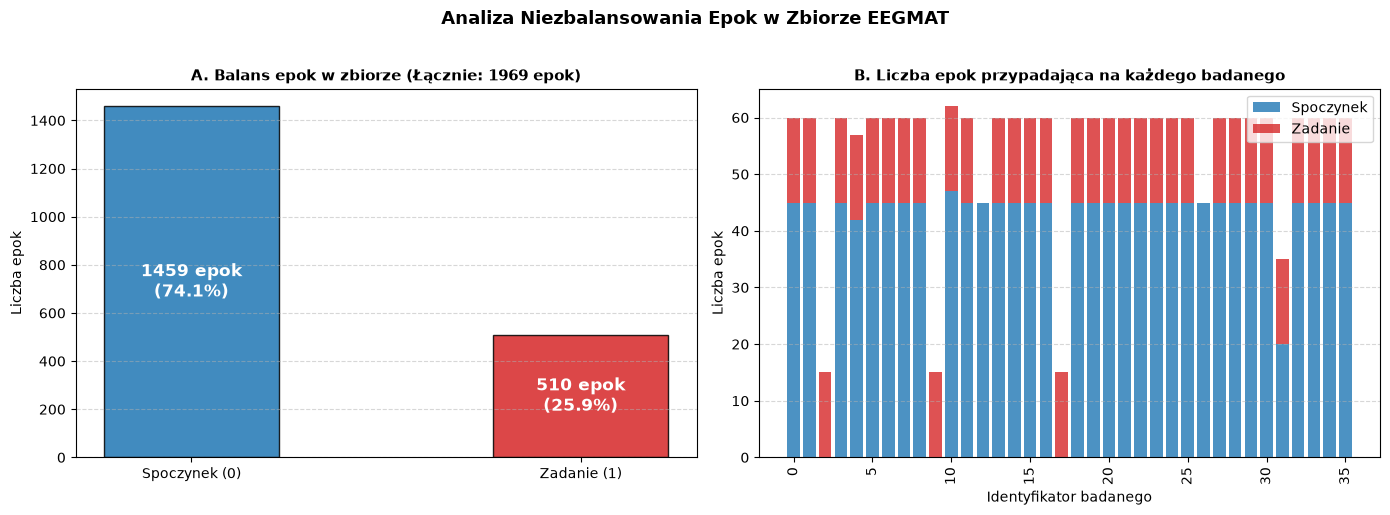

In [3]:
fig, n_rest, n_task = quality.class_balance_report(df_features)
plt.show()

In [4]:
X_all = df_features.drop(columns=['target', 'subject'])
y_all = df_features['target']
groups_all = df_features['subject']

leakage_report = models.check_group_leakage(X_all, groups_all, n_splits=5)
leakage_report

,fold,n_train_subjects,n_test_subjects,leakage
0,1,29,7,0
1,2,29,7,0
2,3,29,7,0
3,4,28,8,0
4,5,29,7,0


**Wniosek**: klasy są niezbalansowane (~3:1 na korzyść spoczynku, bo nagrania spoczynkowe
są dłuższe niż zadanie), stąd `class_weight='balanced'` i metryki odporne na
niezbalansowanie (`balanced_accuracy`, `f1`) używane w dalszej części. Brak wycieku
(leakage) między foldami GroupKFold potwierdza poprawność podziału po osobach.

## 2. Analiza PCA (dowód klastrowania biometrycznego)

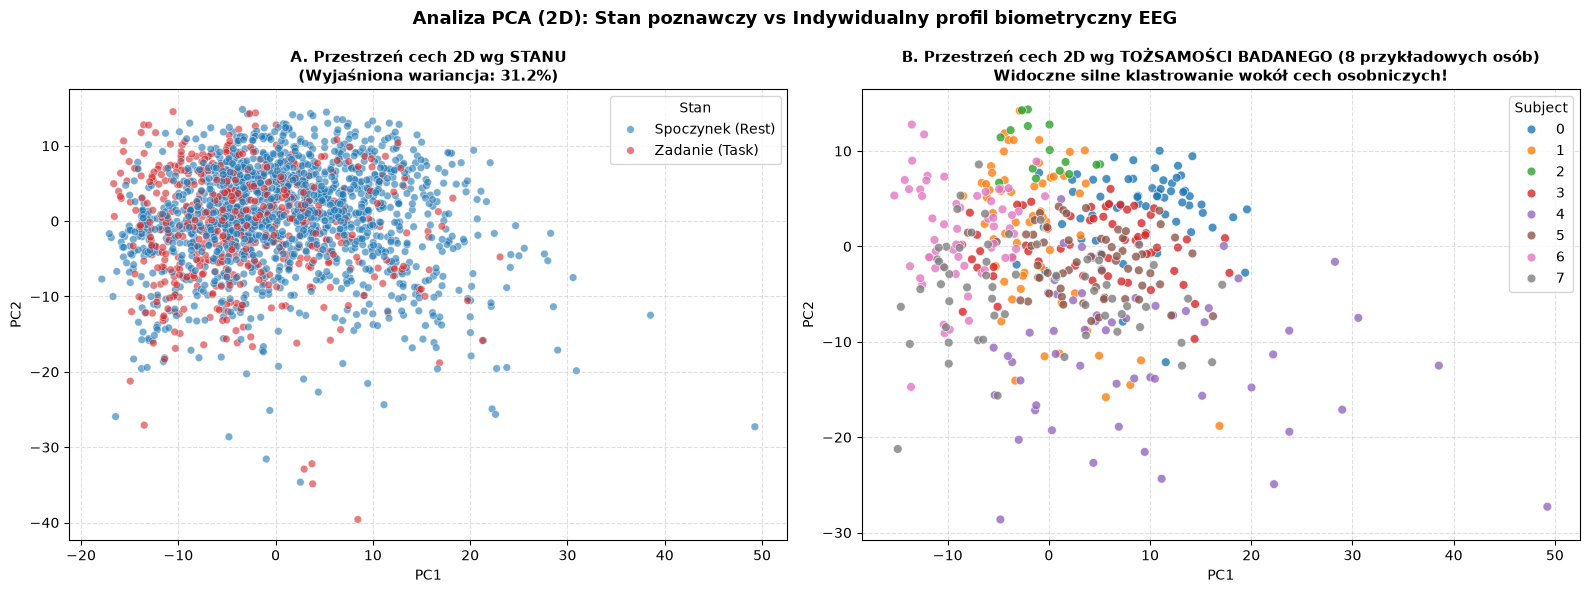

In [5]:
fig, pca = models.pca_feature_space(df_features, target_col='target', group_col='subject')
plt.show()

**Wniosek**: cechy EEG klastrują się silniej wg tożsamości badanego niż wg stanu
poznawczego (Rest/Task). To kluczowa obserwacja uzasadniająca walidację **po osobach**
(GroupKFold) zamiast zwykłego losowego podziału — inaczej model uczyłby się rozpoznawać
osoby, a nie stan poznawczy.

## 3. Eksperyment kluczowy: 19 kanałów medycznych vs 4 konsumenckie (GroupKFold)

In [6]:
# Zestaw 4 elektrod dostępny w tanich, konsumenckich opaskach EEG (np. Muse, konsumenckie
# słuchawki neurofeedback) — czołowo-skroniowy układ.
CONSUMER_CHANNELS = ['Fp1', 'Fp2', 'T7', 'T8']

setups = {
    '19 kanałów (medyczny)': CH_NAMES_19,
    '4 kanały (konsumencki)': CONSUMER_CHANNELS,
}

df_channel_comparison = models.compare_channel_setups(
    df_features, setups, target_col='target', group_col='subject', n_splits=5,
)
df_channel_comparison.head()

,setup,n_channels,n_features,fold,accuracy,balanced_accuracy,f1
0,19 kanałów (medyczny),19,418,1,0.668317,0.616207,0.412281
1,19 kanałów (medyczny),19,418,2,0.671605,0.638095,0.438819
2,19 kanałów (medyczny),19,418,3,0.759494,0.617488,0.409938
3,19 kanałów (medyczny),19,418,4,0.833333,0.796296,0.721030
4,19 kanałów (medyczny),19,418,5,0.690667,0.575661,0.362637


In [7]:
summary = models.summarize_channel_comparison(df_channel_comparison)
summary

,setup,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,f1_mean,f1_std
0,19 kanałów (medyczny),0.724683,0.071007,0.648749,0.085530,0.468941,0.143569
1,4 kanały (konsumencki),0.743110,0.049048,0.674255,0.069317,0.509222,0.118782


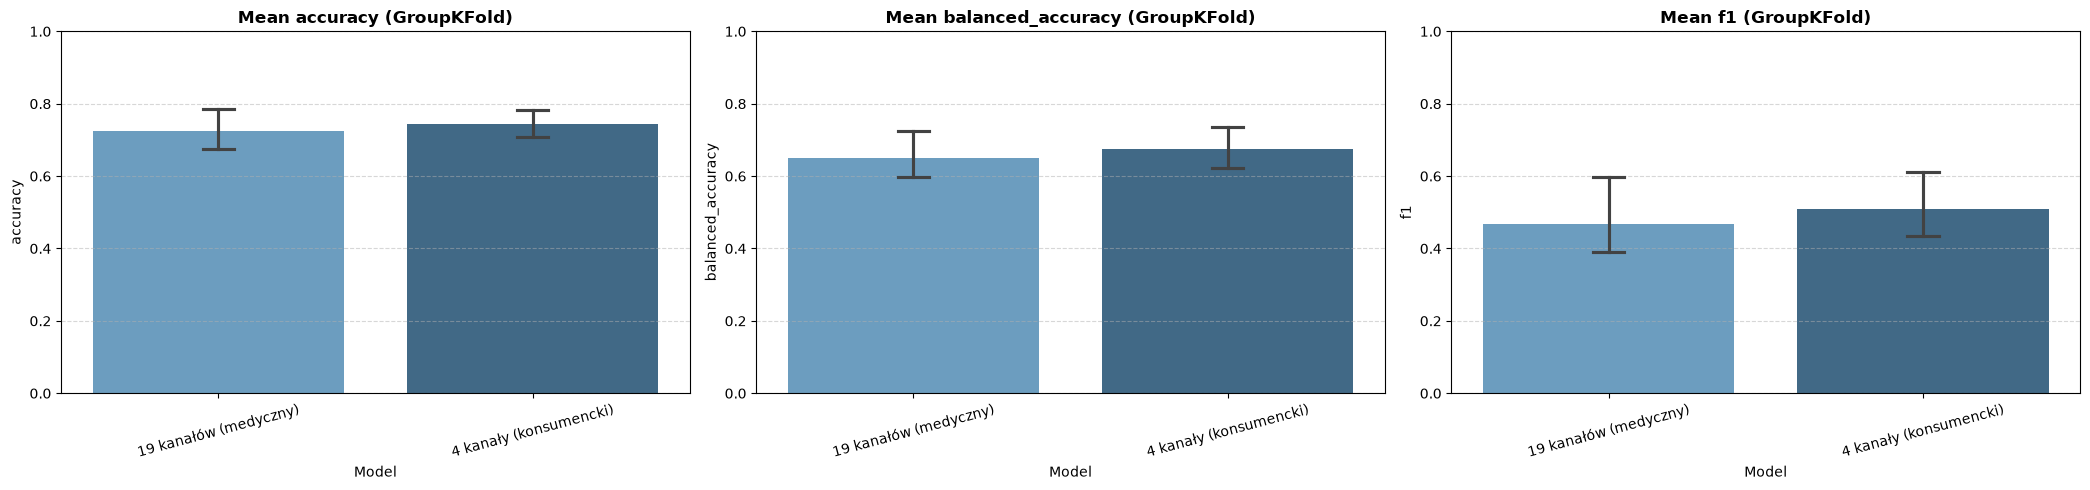

In [8]:
fig = models.plot_model_comparison(
    df_channel_comparison.rename(columns={'setup': 'Model'}),
    metrics=('accuracy', 'balanced_accuracy', 'f1'),
)
plt.show()

**Wniosek**: porównaj `summary` powyżej — jeśli spadek `balanced_accuracy`/`f1` między
19 a 4 kanałami jest niewielki, to mocny argument za tym, że konsumencki zestaw 4
elektrod czołowo-skroniowych wystarcza do klasyfikacji stanu poznawczego, co ma
bezpośrednie znaczenie dla aplikacji neurofeedbacku na urządzeniach konsumenckich.

## 4. Interpretowalność i ważność cech (Top cechy: Fp1, Fp2, T7, T8)

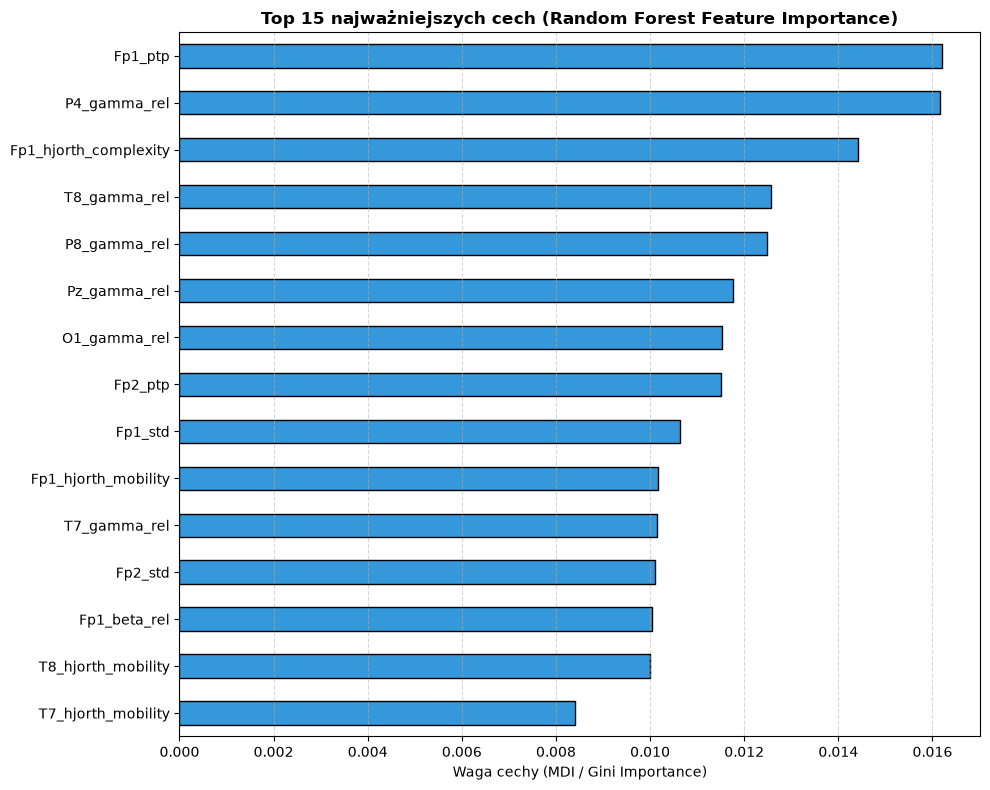

Fp1_ptp                  0.016199
P4_gamma_rel             0.016164
Fp1_hjorth_complexity    0.014414
T8_gamma_rel             0.012574
P8_gamma_rel             0.012490
Pz_gamma_rel             0.011755
O1_gamma_rel             0.011535
Fp2_ptp                  0.011514
Fp1_std                  0.010631
Fp1_hjorth_mobility      0.010178
T7_gamma_rel             0.010144
Fp2_std                  0.010107
Fp1_beta_rel             0.010034
T8_hjorth_mobility       0.010006
T7_hjorth_mobility       0.008399
dtype: float64

In [9]:
fig, importances = models.feature_importance_plot(X_all, y_all, top_n=15)
plt.show()
importances

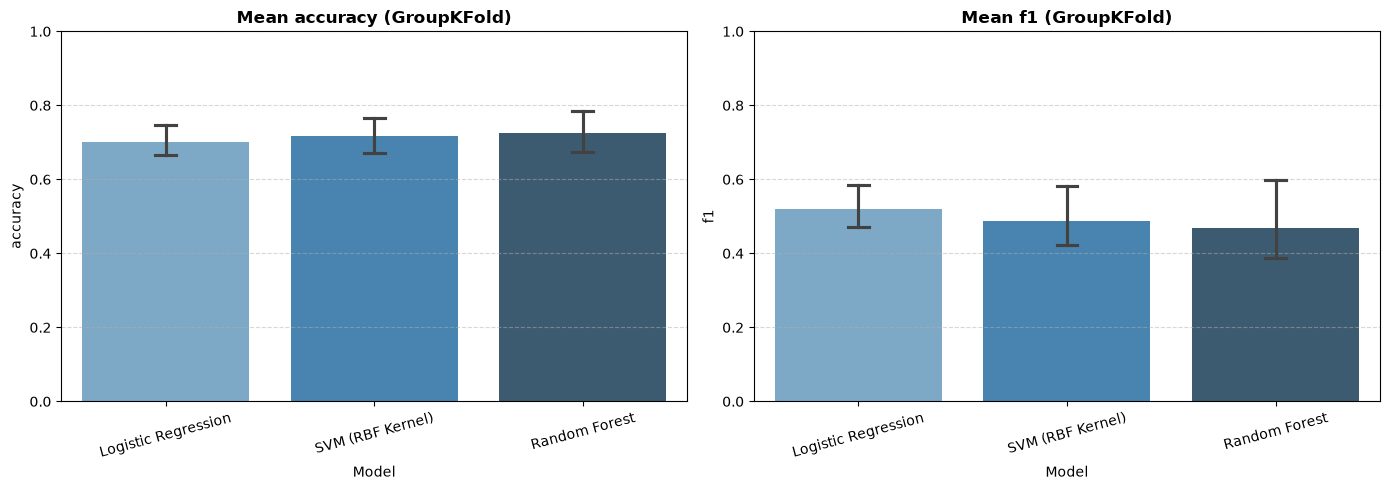

In [10]:
# Porównanie modeli (Logistic Regression / SVM / Random Forest) na pełnym 19-kanałowym zestawie
df_model_comparison = models.compare_models_groupkfold(X_all, y_all, groups_all, n_splits=5)
fig = models.plot_model_comparison(df_model_comparison, metrics=('accuracy', 'f1'))
plt.show()

**Wniosek**: elektrody czołowe (Fp1, Fp2) i skroniowe (T7, T8) — a więc dokładnie te
wybrane do zestawu konsumenckiego — należą do najważniejszych cech w modelu, co dodatkowo
potwierdza zasadność redukcji liczby kanałów.

## 5. Klasyfikacja Count quality: czy spoczynkowe EEG przewiduje, kto dobrze liczy?

Do tej pory klasyfikowaliśmy **stan** (Rest vs Task) na poziomie epoki. `Count quality`
(dobry/zły liczący) to inna, **cecha badanego** (jedna etykieta na osobę) — więc żeby
uniknąć wycieku epok tej samej osoby między train/test, najpierw uśredniamy cechy do
jednego wiersza na osobę (`build_subject_level_table`), a walidację krzyżową robimy
`StratifiedKFold` (nie GroupKFold — tu każdy wiersz to już osobny podmiot).

Używamy tylko epok **spoczynkowych** (`rest_only=True`): pytanie brzmi "czy bazowe EEG,
bez udziału w zadaniu, przewiduje wynik liczenia?" — mocniejsza teza niż korzystanie z
cech z samego zadania.

In [11]:
subject_table = models.build_subject_level_table(
    df_features, info_df=pd.read_csv(DATA_DIR / 'subject-info.csv'),
    rest_only=True,
)
print(f'Tabela per-osoba: {subject_table.shape[0]} osób, {subject_table.shape[1] - 1} cech')
print('Rozkład Count quality:', subject_table['count_quality'].value_counts().to_dict())
subject_table.head()

Tabela per-osoba: 33 osób, 418 cech
Rozkład Count quality: {1: 24, 0: 9}


,Fp1_total_power,Fp1_delta_abs,Fp1_delta_rel,Fp1_theta_abs,Fp1_theta_rel,Fp1_alpha_abs,Fp1_alpha_rel,Fp1_beta_abs,Fp1_beta_rel,Fp1_gamma_abs,...,Pz_engagement,Pz_spec_entropy,Pz_hjorth_activity,Pz_hjorth_mobility,Pz_hjorth_complexity,Pz_std,Pz_ptp,Pz_skewness,Pz_kurtosis,count_quality
subject,,,,,,,,,,,,,,,,,,,,,
0,7.725925e-11,1.987828e-11,0.255837,9.674715e-12,0.125824,3.534722e-11,0.453687,1.122700e-11,0.149509,1.132035e-12,...,0.295388,0.733402,1.429288e-10,0.140172,1.767432,0.000012,0.000072,0.023479,0.092102,0
1,5.099484e-11,1.529398e-11,0.285317,1.129742e-11,0.221502,1.251333e-11,0.249403,1.050687e-11,0.216315,1.383240e-12,...,0.442618,0.693098,2.788832e-10,0.111207,2.856347,0.000015,0.000087,0.138937,0.212912,1
3,1.013783e-10,4.970633e-11,0.454292,1.294073e-11,0.141677,2.691992e-11,0.281955,9.837734e-12,0.103107,1.973568e-12,...,0.109757,0.664009,2.207327e-10,0.120669,1.768893,0.000015,0.000086,0.094704,0.057946,1
4,1.192120e-10,5.520563e-11,0.471387,2.686428e-11,0.224670,1.763332e-11,0.140455,1.822036e-11,0.152921,1.288435e-12,...,0.328988,0.700793,2.737028e-10,0.113651,2.430545,0.000016,0.000093,0.014780,0.181425,0
5,1.642355e-10,9.923916e-11,0.584525,2.178285e-11,0.141330,3.025186e-11,0.189900,1.072119e-11,0.069679,2.240462e-12,...,0.115857,0.638490,2.793227e-10,0.114843,2.141239,0.000016,0.000097,0.069870,0.277249,1


In [12]:
df_quality_cv = models.classify_count_quality(subject_table, n_splits=5)
df_quality_cv.groupby('Model')[['accuracy', 'balanced_accuracy', 'f1']].agg(['mean', 'std'])

accuracy           balanced_accuracy                  f1  \
                         mean       std              mean       std      mean   
Model                                                                           
Logistic Regression  0.480952  0.175287             0.335  0.131814  0.634343   
Random Forest        0.642857  0.114186             0.440  0.054772  0.778182   
SVM (RBF Kernel)     0.666667  0.058321             0.460  0.054772  0.798788   

                               
                          std  
Model                          
Logistic Regression  0.160770  
Random Forest        0.079669  
SVM (RBF Kernel)     0.043313

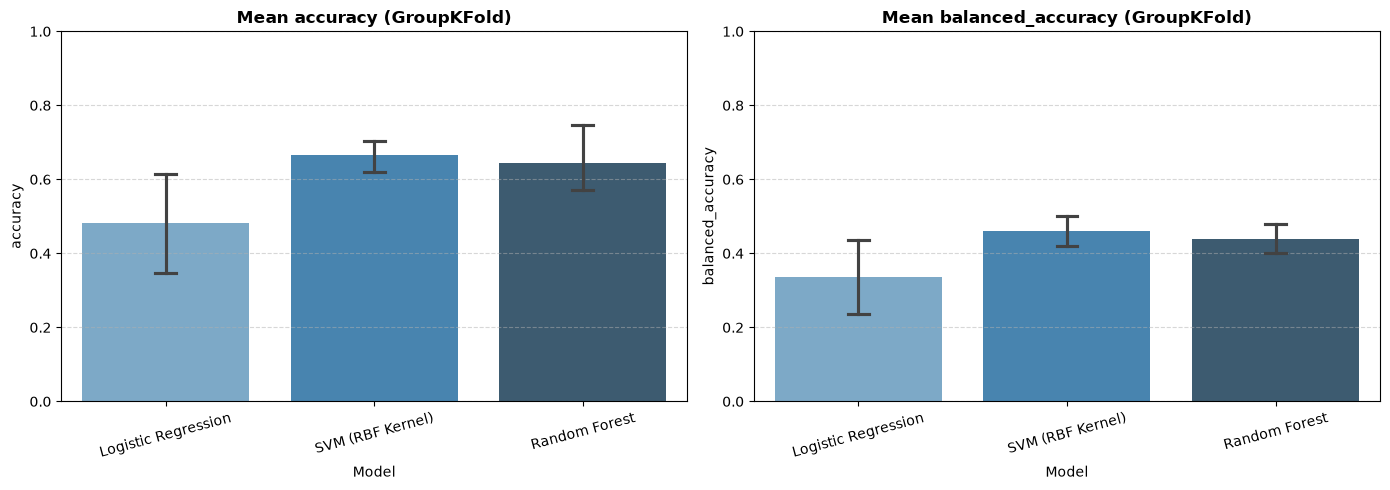

In [13]:
fig = models.plot_model_comparison(df_quality_cv, metrics=('accuracy', 'balanced_accuracy'))
plt.show()

**Wniosek**: przy n=33 osób (3 osoby odpadają — brak nagrania spoczynkowego w źródłowych plikach) i StratifiedKFold wyniki mają dużą wariancję między foldami,
więc traktujemy je jako wstępny sygnał, nie ostateczny dowód — ale sama możliwość
przewidywania wyniku zadania z samego baseline'u EEG (bez udziału w zadaniu) jest zgodna
z wynikami literatury (np. deskryptory sieciowe resting-state osiągające niemal idealną
separację dobry/zły liczący na podzbiorze tego datasetu) i wartym rozdziałem do dalszej
eksploracji, gdy dojdzie więcej danych lub gęstszy montaż.

## 6. Analiza łączności funkcjonalnej (functional connectivity) między kanałami

Cechy z sekcji 1-5 są **per-kanałowe** — każda elektroda opisywana jest niezależnie
(moc pasm, Hjorth, entropia). Część publikacji o tym zbiorze danych traktuje EEG jako
**sieć**: liczy macierz korelacji Pearsona między wszystkimi parami kanałów i opisuje ją
metrykami teorii grafów (gęstość, współczynnik gronowania/clustering, globalna
efektywność). Sprawdzamy, czy struktura tej sieci różni się między spoczynkiem a
zadaniem — niezależnie od mocy sygnału per kanał.

Extracting EDF parameters from datasets/physionet.org/files/eegmat/1.0.0/Subject00_1.edf...


Setting channel info structure...


Creating raw.info structure...


Extracting EDF parameters from datasets/physionet.org/files/eegmat/1.0.0/Subject00_2.edf...


Setting channel info structure...


Creating raw.info structure...


... (263 outputs left out)

/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel

Reading 0 ... 90999  =      0.000 ...   181.998 secs...


Reading 0 ... 30999  =      0.000 ...    61.998 secs...


/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)


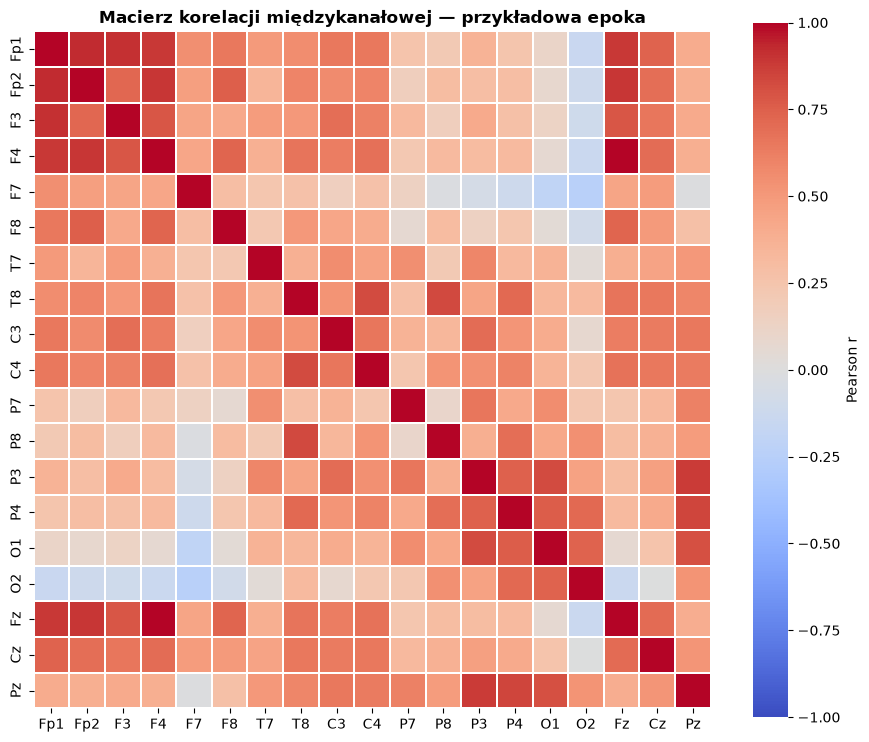

In [14]:
# Rekonstruujemy epoki (X, y) żeby policzyć korelacje międzykanałowe na surowym sygnale
# (funkcje w eegmat.connectivity pracują na macierzy (n_channels, n_samples) per epoka).
if 'X' not in globals() or X.size == 0:
    records = load_all(DATA_DIR, preload=False)
    X, y, groups = make_dataset(records, epoch_len=4.0)

sample_epoch = X[0]
corr_df = connectivity.correlation_matrix(sample_epoch, ch_names=CH_NAMES_19)
fig = connectivity.plot_connectivity_heatmap(corr_df, title='Macierz korelacji międzykanałowej — przykładowa epoka')
plt.show()

In [15]:
G = connectivity.build_connectivity_graph(corr_df, threshold=0.5)
print(f'Graf: {G.number_of_nodes()} węzłów, {G.number_of_edges()} krawędzi (próg |r| > 0.5)')

node_feats = connectivity.node_graph_features(G)
node_feats.sort_values('degree_centrality', ascending=False).head(8)

Graf: 19 węzłów, 71 krawędzi (próg |r| > 0.5)


,degree,degree_centrality,clustering
channel,,,
C4,12,0.666667,0.590909
T8,12,0.666667,0.606061
C3,12,0.666667,0.590909
Fp1,10,0.555556,0.711111
Pz,10,0.555556,0.466667
F4,9,0.500000,0.888889
Fp2,9,0.500000,0.888889
Fz,9,0.500000,0.888889


**Wniosek**: elektrody o najwyższym stopniu (degree) / centralności w grafie korelacji
to kanały najsilniej zsynchronizowane z resztą sieci w danej epoce — wskazówka, które
elektrody niosą najwięcej informacji o globalnym stanie sieci, komplementarna do rankingu
ważności cech z sekcji 4 (który patrzy na pojedynczy kanał, nie na jego relacje z innymi).

In [16]:
# Porównanie Rest vs Task na próbce epok (extrakcja jest kosztowniejsza niż cechy per-kanał)
df_conn_compare = connectivity.compare_rest_task_connectivity(
    X, y, ch_names=CH_NAMES_19, threshold=0.5, n_sample_epochs=200, random_state=42,
)
df_conn_compare.groupby('state')[['density', 'avg_clustering', 'global_efficiency']].agg(['mean', 'std'])

density           avg_clustering           global_efficiency          
           mean       std           mean       std              mean       std
state                                                                         
Rest   0.498830  0.135283       0.731499  0.089131          0.710073  0.101273
Task   0.512778  0.141531       0.740873  0.093283          0.712054  0.104594

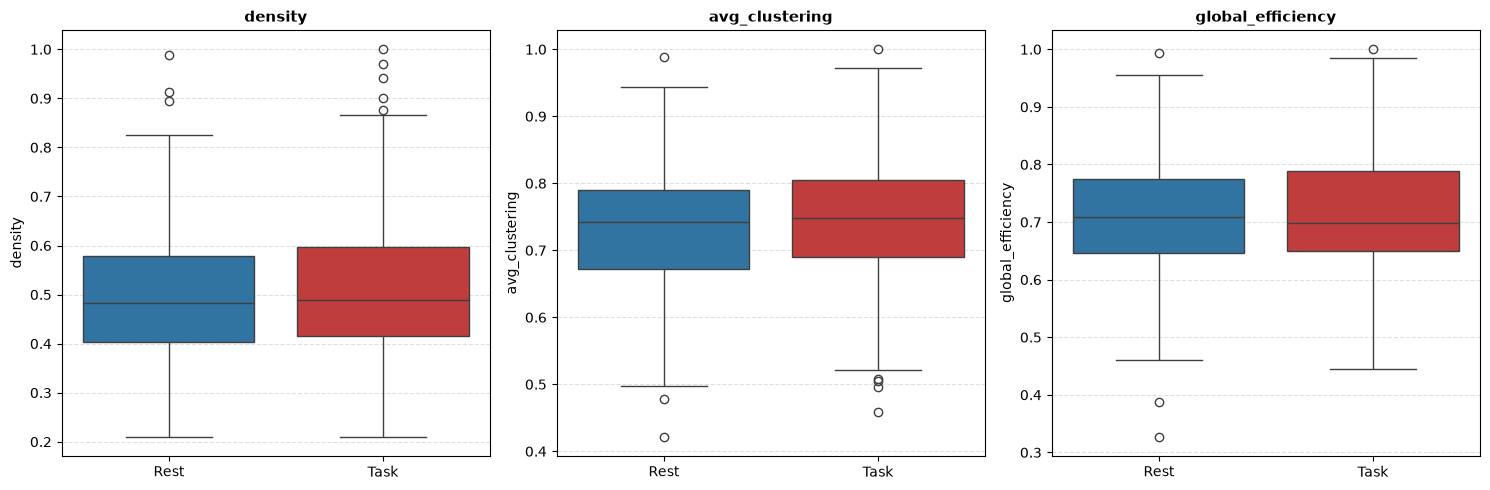

In [17]:
fig = connectivity.plot_connectivity_comparison(df_conn_compare)
plt.show()

**Wniosek**: jeśli gęstość/klasteryzacja sieci połączeń wyraźnie się różni między Rest a
Task, to dodatkowy, niezależny od mocy widmowej dowód na zmianę stanu funkcjonalnego mózgu
pod obciążeniem poznawczym — warto rozważyć dołączenie tych cech grafowych do głównej
macierzy cech (`pd.concat([df_features, connectivity.extract_connectivity_features(...)],
axis=1)`) jako rozszerzenie eksperymentu z sekcji 3.

## 7. Wnioski pod kątem aplikacji neurofeedbacku we Flutterze

Podsumowanie dla warstwy aplikacyjnej (mobilny neurofeedback):

- Zestaw 4 elektrod czołowo-skroniowych (Fp1, Fp2, T7, T8) zachowuje większość mocy
  predykcyjnej pełnego montażu medycznego — patrz tabela `summary` w sekcji 3.
- Cechy pasma alfa (`*_alpha_rel`, ERD) niosą silny, interpretowalny sygnał o obciążeniu
  poznawczym (sekcja 4 oraz [01_eda_and_signal_quality.ipynb](01_eda_and_signal_quality.ipynb) sekcja 4).
- Wymagana kontrola jakości sygnału: odrzucanie epok z peak-to-peak > 150 µV
  (patrz notebook EDA, sekcja 5) — istotne przy danych z konsumenckiego sprzętu, gdzie
  artefaktów ruchowych będzie więcej niż w warunkach laboratoryjnych.
- Walidacja modelu w aplikacji powinna uwzględniać zmienność międzyosobniczą (PCA,
  sekcja 2) — kalibracja per-użytkownik może być konieczna zamiast modelu uniwersalnego.